# Sieci neuronowe – ćwiczenie 3, część 2
## Optymalizacja sieci wielowarstwowej: tryby uczenia, inicjalizacja wag, ADAM · zbiór Heart Disease (Cleveland)

**Dawid Pilarski** &nbsp;&nbsp; **Nr albumu:** 280468

> Kod przygotowany z pomocą narzędzia AI (Claude).

---

### Najważniejsze wyniki

| | |
|---|---|
| sieć | 17-17-17-17-17-17-1 (5 warstw ukrytych, ReLU), sigmoida + entropia krzyżowa, ta sama implementacja co w cz. 1 |
| punkt siodłowy (funkcja 2D) | prosty gradient ucieka po **91** krokach, ADAM po **6** |
| pełny zbiór / paczki po 32 / pojedyncze przykłady | koszt ≤ 0,3 po 398 / 66 / **4** epokach; podobna liczba kroków (398–724), a czas 1000 epok ok. 0,3 / 0,8 / 15 s |
| inicjalizacja | N(0; 0,01): gradient ok. $10^{-8}$, sieć stoi; N(0; 1): koszt startowy 12, F1 tylko 0,50; **He**: F1 0,77; N(0; 10): **NaN** po 1–2 epokach albo martwa sieć |
| GD vs ADAM | start He: koszt ≤ 0,3 po 398 (GD) vs **10–63** epokach (ADAM); start N(0; 0,01): GD nie rusza w 3000 epok, ADAM wychodzi z plateau po 17–90 epokach |
| jakość | najlepsze F1 testowe przy early stopping ok. 0,76–0,78 niezależnie od metody, jeśli uczenie w ogóle ruszy |

**Spis treści:** 1. Cel · 2. Implementacja · 3. Punkt siodłowy · 4. Pełny zbiór, paczki, pojedyncze przykłady · 5. Inicjalizacja wag · 6. Prosty gradient a ADAM · 7. Podsumowanie · 8. Wnioski

> 🗣 **Co mówię:**
>
> Na początek podsumowanie. W tej części do sieci z części 1 dopisałem uczenie w paczkach i na pojedynczych przykładach, inicjalizację He i optymalizator ADAM.
>
> Najważniejsze wyniki: w punkcie siodłowym prosty gradient ucieka po 91 krokach, a ADAM po 6. Inicjalizacja decyduje, czy uczenie w ogóle ruszy: przy wagach 0,01 sieć stoi, przy odchyleniu 10 wychodzi NaN, a He działa od razu. ADAM wychodzi z płaskowyżu, na którym prosty gradient stoi przez 3000 epok.

## 1. Cel ćwiczenia

Uczenie sieci z dwiema lub więcej warstwami to optymalizacja **niewypukła**. Głównym problemem nie są jednak minima lokalne, tylko **punkty siodłowe i płaskowyże**: miejsca, w których gradient jest (prawie) zerowy, choć nie jest to minimum. W tej części implementuję i porównuję:

- uczenie na **pełnym zbiorze**, w **paczkach** (mini-batch) i na **pojedynczych przykładach** (SGD),
- inicjalizację wag z rozkładu o **odchyleniu 1**, inicjalizację **He** i inicjalizację **celowo zepsutą** (odchylenie 10), a dla porównania także N(0; 0,01) z cz. 1,
- **prosty spadek gradientu** i optymalizator **ADAM**.

Żeby problemy optymalizacji było widać, używam sieci z **5 warstwami ukrytymi** po 17 neuronów (o 4 więcej niż potrzeba na tym zbiorze) i stałej liczby epok dobranej do każdego eksperymentu, a wagi z najniższym kosztem walidacyjnym zapamiętuję (early stopping).

> 🗣 **Co mówię:**
>
> Lista mówi, że w sieciach z dwiema i więcej warstwami głównym problemem nie są minima lokalne, tylko punkty siodłowe i płaskowyże, czyli miejsca, gdzie gradient jest prawie zerowy.
>
> Porównuję trzy rzeczy z listy: tryb uczenia, inicjalizację wag i prosty gradient z ADAM-em. Żeby problemy było widać, sieć jest celowo głęboka: 5 warstw ukrytych po 17 neuronów.

## 2. Implementacja

### 2.1. Tryby uczenia i optymalizatory

| element | wzór / działanie |
|---|---|
| pełny zbiór (batch GD) | gradient z całego zbioru treningowego, **1 krok na epokę** |
| paczki (mini-batch) | zbiór w losowej kolejności dzielony na paczki po 32, **6 kroków na epokę** |
| pojedyncze przykłady (SGD) | krok po każdym przykładzie, **181 kroków na epokę** |
| prosty gradient | $w_t = w_{t-1} - \alpha\, g_t$ |
| ADAM | $m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t$, $\;v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2$ |
| | $\hat m_t = \dfrac{m_t}{1-\beta_1^t}$, $\;\hat v_t = \dfrac{v_t}{1-\beta_2^t}$, $\;w_t = w_{t-1} - \alpha \dfrac{\hat m_t}{\sqrt{\hat v_t} + \varepsilon}$ |
| inicjalizacja He | $W \sim N\left(0; \sqrt{2 / d_{in}}\right)$ – zachowuje wariancję sygnału przy ReLU |

ADAM liczy dla każdej wagi osobno dwie średnie kroczące: $m$ (kierunek ostatnich kroków, czyli **momentum**) i $v$ (kwadrat gradientu, czyli **skalowanie kroku** odwrotnością jego wielkości). Obie startują od zera, dlatego potrzebna jest korekcja biasu. Domyślnie $\beta_1 = 0{,}9$, $\beta_2 = 0{,}999$, $\varepsilon = 10^{-8}$.

Koszt treningowy i walidacyjny mierzę po każdej epoce na **całych** zbiorach, niezależnie od trybu, żeby krzywe były porównywalne.

> 🗣 **Co mówię:**
>
> W tabeli są wzory. Tryby różnią się tym, na ilu pacjentach liczę gradient przed krokiem: na wszystkich 181, na paczce 32 albo na jednym.
>
> ADAM trzyma dla każdej wagi dwie średnie. m to średnia gradientu, czyli momentum: krok pamięta kierunek. v to średnia kwadratu gradientu, czyli skalowanie: dzielę krok przez typową wielkość gradientu, więc na płaskim terenie krok nie maleje. Obie startują od zera, dlatego jest korekcja biasu.
>
> He losuje wagi z odchyleniem pierwiastek z 2 przez liczbę wejść, żeby sygnał nie malał ani nie rósł z warstwy na warstwę.

In [1]:
import os, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, os.getcwd())
from data import load_splits          # przygotowanie danych z ćw. 1

SEED = 42
pd.set_option("display.precision", 4)

# wspólny styl wykresów
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (12, 4), "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold",
    "legend.frameon": False,
})
C = {"train": "#1f5f8b", "val": "#e07b39", "ref": "#808080",
     "full": "#1f5f8b", "minibatch": "#3a9d5d", "single": "#c8553d",
     "gd": "#808080", "adam_small": "#1f5f8b", "adam_big": "#e07b39"}

def rys(fig, nr, tytul):
    fig.suptitle(f"Rys. {nr}. {tytul}", fontsize=12, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout()
    plt.show()

Pierwsza komórka: importy (także `time`, do mierzenia czasu uczenia), styl wykresów, kolory i funkcja `rys`, która podpisuje rysunki.

In [2]:
def sigmoid(z):
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out

def bce(y, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

def metrics(y, p, thr=0.5):
    yhat = (p >= thr).astype(float)
    tp = np.sum((yhat == 1) & (y == 1)); fp = np.sum((yhat == 1) & (y == 0))
    fn = np.sum((yhat == 0) & (y == 1)); tn = np.sum((yhat == 0) & (y == 0))
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return dict(precision=prec, recall=rec, f1=f1, accuracy=(tp + tn) / len(y))

`sigmoid` (stabilna numerycznie), `bce` (entropia krzyżowa) i `metrics` (precision, recall, F1, accuracy przy progu 0,5) – te same funkcje co w części 1.

### 2.2. Sieć z części 1 (moduły z `forward` i `backward`)

In [3]:
class Linear:
    # init="he": N(0; sqrt(2 / n_in)), inaczej N(0; scale)
    def __init__(self, n_in, n_out, rng, init="he", scale=1.0):
        std = np.sqrt(2.0 / n_in) if init == "he" else scale
        self.W = rng.normal(0.0, std, (n_out, n_in))
        self.b = np.zeros(n_out)

    def forward(self, X):
        self.X = X
        return X @ self.W.T + self.b

    def backward(self, dY):
        self.dW = dY.T @ self.X
        self.db = dY.sum(0)
        return dY @ self.W

class ReLU:
    def forward(self, X):
        self.mask = X > 0
        return X * self.mask

    def backward(self, dY):
        return dY * self.mask

class SigmoidBCE:
    def forward(self, z, y):
        self.p, self.y = sigmoid(z), y
        return bce(y, self.p)

    def backward(self):
        return ((self.p - self.y) / len(self.y))[:, None]

class MLP:
    def __init__(self, n_in, hidden, init="he", scale=1.0, seed=SEED):
        rng = np.random.default_rng(seed)
        self.layers, prev = [], n_in
        for h in hidden:
            self.layers += [Linear(prev, h, rng, init, scale), ReLU()]
            prev = h
        self.layers.append(Linear(prev, 1, rng, init, scale))
        self.linears = [l for l in self.layers if isinstance(l, Linear)]
        self.loss_fn = SigmoidBCE()

    def forward(self, X):
        for layer in self.layers:
            X = layer.forward(X)
        return X[:, 0]

    def predict_proba(self, X):
        return sigmoid(self.forward(X))

    def loss_and_grad(self, X, y):
        loss = self.loss_fn.forward(self.forward(X), y)
        d = self.loss_fn.backward()
        for layer in reversed(self.layers):
            d = layer.backward(d)
        return loss

    def params_and_grads(self):
        return [pair for l in self.linears for pair in ((l.W, l.dW), (l.b, l.db))]

    def get_params(self):
        return [(l.W.copy(), l.b.copy()) for l in self.linears]

    def set_params(self, params):
        for l, (W, b) in zip(self.linears, params):
            l.W, l.b = W.copy(), b.copy()

Sieć z części 1 z jedną zmianą: `Linear` ma parametr `init`. Dla `init="he"` losuje wagi z $N\left(0; \sqrt{2/d_{in}}\right)$, a w przeciwnym razie z $N(0; \text{scale})$, np. `scale=0.01`, `1.0` albo `10.0`.
`params_and_grads` zwraca pary (wagi, gradient), żeby optymalizator mógł zrobić krok, a `get_params` / `set_params` zapisują i przywracają wagi (early stopping).

### 2.3. Optymalizatory i pętla uczenia

In [4]:
class GD:
    # prosty spadek gradientu: w <- w - lr * g
    def __init__(self, lr=0.01):
        self.lr = lr

    def step(self, pairs):
        for w, g in pairs:
            w -= self.lr * g

class Adam:
    # m: średnia krocząca gradientu (momentum), v: średnia krocząca kwadratu gradientu (skalowanie kroku)
    def __init__(self, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.beta1, self.beta2, self.eps = lr, beta1, beta2, eps
        self.m, self.v, self.t = None, None, 0

    def step(self, pairs):
        if self.m is None:                                  # m i v startują od zera
            self.m = [np.zeros_like(w) for w, _ in pairs]
            self.v = [np.zeros_like(w) for w, _ in pairs]
        self.t += 1
        for (w, g), m, v in zip(pairs, self.m, self.v):
            m *= self.beta1; m += (1 - self.beta1) * g
            v *= self.beta2; v += (1 - self.beta2) * g * g
            m_hat = m / (1 - self.beta1 ** self.t)          # korekcja biasu
            v_hat = v / (1 - self.beta2 ** self.t)
            w -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

Dwa optymalizatory z tą samą metodą `step`:
- `GD`: $w \leftarrow w - \alpha g$,
- `Adam`: dla każdej wagi trzyma `m` (średnia gradientu, momentum) i `v` (średnia kwadratu gradientu), oba startują od zera; `t` to numer kroku do korekcji biasu $1 - \beta^t$.

In [5]:
def train(model, opt, X, y, Xv, yv, mode="full", batch=32, epochs=500, seed=SEED):
    # full: 1 krok na epokę, minibatch: paczki po `batch` (ceil(N/batch) kroków), single: N kroków na epokę
    rng = np.random.default_rng(seed)
    n = len(y)
    bs = {"full": n, "minibatch": batch, "single": 1}[mode]
    h = {k: [] for k in ["epoch", "step", "loss", "val_loss", "grad_norms", "time"]}
    best, steps, t0 = (np.inf, None, 0), 0, time.perf_counter()

    def log(ep):
        loss = model.loss_and_grad(X, y)                    # pełny koszt i gradient tylko do pomiaru
        h["epoch"].append(ep); h["step"].append(steps); h["loss"].append(loss)
        h["val_loss"].append(bce(yv, model.predict_proba(Xv)))
        h["grad_norms"].append([float(np.sqrt(np.sum(l.dW ** 2))) for l in model.linears])
        h["time"].append(time.perf_counter() - t0)
        return loss

    log(0)
    for ep in range(1, epochs + 1):
        order = rng.permutation(n) if bs < n else np.arange(n)
        for s in range(0, n, bs):
            idx = order[s:s + bs]
            model.loss_and_grad(X[idx], y[idx])
            opt.step(model.params_and_grads())
            steps += 1
        loss = log(ep)
        if h["val_loss"][-1] < best[0] - 1e-9:
            best = (h["val_loss"][-1], model.get_params(), ep)
        if not np.isfinite(loss):
            break
    model.history = h
    model.best_val_loss, model.best_params, model.best_epoch = best
    return model

def epochs_to(h, target, key="loss"):
    return next((int(e) for e, v in zip(h["epoch"], h[key]) if v <= target), None)

def early_f1(model, X, y):
    # F1 dla wag z najniższym kosztem walidacyjnym (None, jeśli koszt walidacyjny nigdy nie był skończony)
    if model.best_params is None:
        return None
    last = model.get_params(); model.set_params(model.best_params)
    f1 = metrics(y, model.predict_proba(X))["f1"]; model.set_params(last)
    return f1

def mean_or_dash(vals, nd=3):
    vals = [v for v in vals if v is not None]
    return round(float(np.mean(vals)), nd) if vals else "—"

NET = (17,) * 5      # 5 warstw ukrytych po 17 neuronów
SEEDS = (0, 1, 2)
PLATEAU, TARGET = 0.6, 0.3

(Xtr, ytr), (Xva, yva), (Xte, yte), names = load_splits(seed=SEED)
d = Xtr.shape[1]
print(f"sieć {d}-{'-'.join(map(str, NET))}-1, parametrów: {sum(l.W.size + l.b.size for l in MLP(d, NET).linears)}")
pd.DataFrame({"liczba pacjentów": [len(ytr), len(yva), len(yte)],
              "odsetek chorych": [ytr.mean(), yva.mean(), yte.mean()]},
             index=["treningowy", "walidacyjny", "testowy"]).round(3).assign(**{"liczba cech": d})

sieć 17-17-17-17-17-17-1, parametrów: 1548


,liczba pacjentów,odsetek chorych,liczba cech
treningowy,181,0.459,17
walidacyjny,61,0.459,17
testowy,61,0.459,17


`train` to pętla uczenia dla trzech trybów: `full` (cały zbiór, 1 krok na epokę), `minibatch` (paczki po 32 w losowej kolejności, 6 kroków na epokę), `single` (każdy pacjent osobno, 181 kroków na epokę).
Po każdej epoce `log` mierzy koszt na **całym** zbiorze treningowym i walidacyjnym, normy gradientów i czas, żeby tryby były porównywalne. Wagi z najniższym kosztem walidacyjnym są zapamiętywane, a przy NaN uczenie się kończy.
`NET = (17,) * 5`: 5 warstw ukrytych po 17 neuronów; `PLATEAU = 0.6` to próg wyjścia z plateau, `TARGET = 0.3` próg „nauczonej” sieci.

> 🗣 **Co mówię:**
>
> Sieć to ta sama z części 1. Dopisałem dwa optymalizatory, GD i Adam, z jedną metodą step, i funkcję train, która uczy w trzech trybach.
>
> Koszt mierzę po każdej epoce na całym zbiorze, niezależnie od trybu, żeby krzywe były porównywalne. Wagi z najlepszej epoki na walidacji zapamiętuję.

### 2.4. Testy poprawności

- dwa kroki ADAM porównuję z obliczeniem ręcznym ze wzorów,
- sprawdzam, że dzięki korekcji biasu pierwszy krok ADAM ma długość α niezależnie od skali gradientu,
- gradient pełnego zbioru musi być średnią gradientów pojedynczych przykładów (koszt to średnia),
- propagację wsteczną porównuję z gradientem numerycznym dla każdej wagi.

In [6]:
# 1) ADAM: dwa kroki liczone ręcznie ze wzorów
b1, b2, lr, eps = 0.9, 0.999, 0.1, 1e-8
w = np.array([1.0, -2.0]); g1, g2 = np.array([0.5, -0.1]), np.array([0.2, 0.3])
opt = Adam(lr, b1, b2, eps); opt.step([(w, g1)]); opt.step([(w, g2)])
m = v = np.zeros(2); w_ref = np.array([1.0, -2.0])
for t, g in enumerate([g1, g2], 1):
    m = b1 * m + (1 - b1) * g; v = b2 * v + (1 - b2) * g * g
    w_ref = w_ref - lr * (m / (1 - b1 ** t)) / (np.sqrt(v / (1 - b2 ** t)) + eps)

# 2) pierwszy krok ADAM ma długość α niezależnie od skali gradientu
first = []
for scale in [1e-3, 1.0, 1e3]:
    w1 = np.zeros(2); Adam(0.01).step([(w1, scale * np.array([1.0, -4.0]))]); first.append(np.abs(w1).max())

# 3) gradient pełnego zbioru = średnia gradientów pojedynczych przykładów
net = MLP(d, (8, 8), seed=1); net.loss_and_grad(Xtr, ytr); full = net.linears[0].dW.copy(); mean = 0
for i in range(len(ytr)):
    net.loss_and_grad(Xtr[i:i + 1], ytr[i:i + 1]); mean = mean + net.linears[0].dW / len(ytr)

# 4) propagacja wsteczna vs gradient numeryczny (cała sieć, 2 warstwy ukryte)
rng = np.random.default_rng(3)
X = rng.normal(size=(20, 5)); y = (rng.random(20) > 0.5).astype(float)
net2 = MLP(5, (6, 4), "normal", 0.5, seed=3); net2.loss_and_grad(X, y); err = 0.0
for l in net2.linears:
    for A, G in [(l.W, l.dW), (l.b, l.db)]:
        for i in np.ndindex(A.shape):
            old = A[i]; A[i] = old + 1e-6; fp = bce(y, net2.predict_proba(X))
            A[i] = old - 1e-6; fm = bce(y, net2.predict_proba(X)); A[i] = old
            err = max(err, abs(G[i] - (fp - fm) / 2e-6))

pd.DataFrame({"wynik": [f"{np.max(np.abs(w - w_ref)):.1e}", " / ".join(f"{x:.4f}" for x in first),
                        f"{np.max(np.abs(full - mean)):.1e}", f"{err:.1e}"]},
             index=["ADAM: różnica vs wzory (2 kroki)", "ADAM: |pierwszy krok| dla g ×1e-3 / ×1 / ×1e3 (α = 0,01)",
                    "gradient pełnego zbioru vs średnia z pojedynczych", "propagacja wsteczna vs gradient numeryczny"])

,wynik
ADAM: różnica vs wzory (2 kroki),0.0e+00
"ADAM: |pierwszy krok| dla g ×1e-3 / ×1 / ×1e3 (α = 0,01)",0.0100 / 0.0100 / 0.0100
gradient pełnego zbioru vs średnia z pojedynczych,2.8e-17
propagacja wsteczna vs gradient numeryczny,1.1e-10


Cztery testy: ADAM porównany z ręcznym rachunkiem ze wzorów (2 kroki), długość pierwszego kroku ADAM dla gradientów od $10^{-3}$ do $10^{3}$, gradient pełnego zbioru jako średnia gradientów pojedynczych pacjentów i propagacja wsteczna porównana z gradientem numerycznym.

> **Wniosek:** ADAM liczy dokładnie wzory z treści, pierwszy krok ma długość α = 0,01 dla gradientów od $10^{-3}$ do $10^{3}$, a gradienty z paczek i z propagacji wstecznej są poprawne.

> 🗣 **Co mówię:**
>
> Sprawdziłem implementację. ADAM zgadza się z rachunkiem ręcznym ze wzorów. Pierwszy krok ADAM ma długość α niezależnie od tego, czy gradient to 0,001 czy 1000, i to jest dokładnie ta własność, która pomaga na płaskowyżu. Gradient z całego zbioru to średnia z pojedynczych, a backward zgadza się z numerycznym do 10⁻¹⁰.

## 3. Punkt siodłowy

Najpierw prosty przykład na płaszczyźnie: $f(x, y) = x^2 + \frac{y^4}{4} - \frac{y^2}{2}$ ma punkt siodłowy w (0; 0) i dwa minima w (0; ±1). Start w (1; 0,0001), czyli prawie dokładnie na „grzbiecie” siodła, α = 0,1 dla obu metod, 150 kroków.

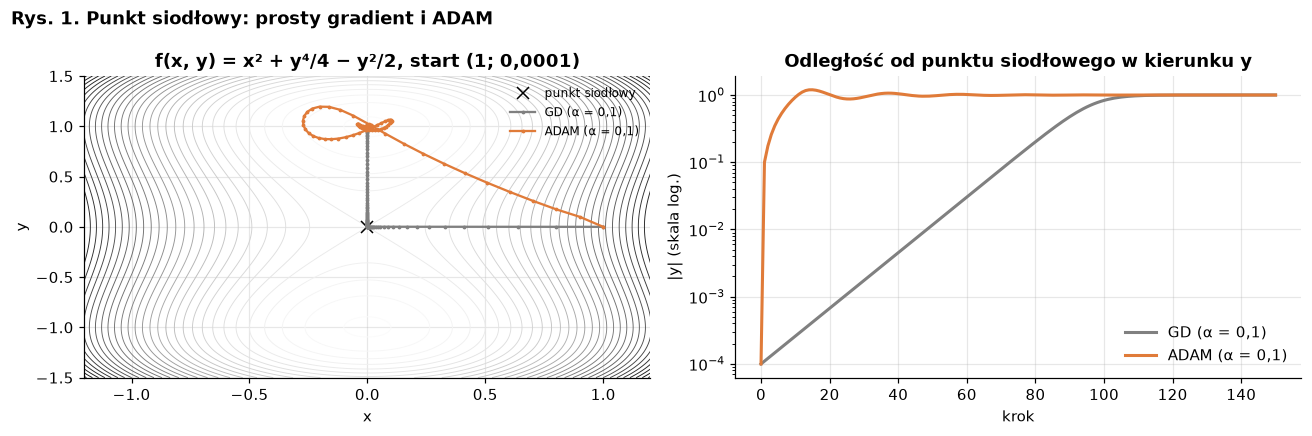

,"krok, w którym |y| > 0,5",punkt końcowy,f końcowe
"GD (α = 0,1)",91,(0.000; 1.000),-0.25
"ADAM (α = 0,1)",6,(-0.000; 1.000),-0.25


In [7]:
def saddle_f(p):
    x, y = p
    return x * x + y ** 4 / 4 - y * y / 2      # punkt siodłowy (0, 0), minima (0, ±1)

def saddle_grad(p):
    x, y = p
    return np.array([2 * x, y ** 3 - y])

def run_saddle(opt, start=(1.0, 1e-4), steps=150):
    p = np.array(start); traj = [p.copy()]
    for _ in range(steps):
        opt.step([(p, saddle_grad(p))]); traj.append(p.copy())
    return np.array(traj)

trajs = {"GD (α = 0,1)": (run_saddle(GD(0.1)), C["gd"]), "ADAM (α = 0,1)": (run_saddle(Adam(0.1)), C["adam_big"])}
fig, ax = plt.subplots(1, 2)
xs, ys = np.meshgrid(np.linspace(-1.2, 1.2, 200), np.linspace(-1.5, 1.5, 200))
ax[0].contour(xs, ys, saddle_f((xs, ys)), levels=30, cmap="Greys", linewidths=0.6)
ax[0].plot(0, 0, "kx", ms=8, label="punkt siodłowy")
rows = {}
for name, (t, col) in trajs.items():
    ax[0].plot(t[:, 0], t[:, 1], ".-", ms=3, c=col, label=name)
    ax[1].plot(np.abs(t[:, 1]), c=col, lw=2, label=name)
    rows[name] = {"krok, w którym |y| > 0,5": int(np.argmax(np.abs(t[:, 1]) > 0.5)),
                  "punkt końcowy": f"({t[-1, 0]:.3f}; {t[-1, 1]:.3f})", "f końcowe": round(saddle_f(t[-1]), 4)}
ax[0].set(xlabel="x", ylabel="y", title="f(x, y) = x² + y⁴/4 − y²/2, start (1; 0,0001)")
ax[1].set(yscale="log", xlabel="krok", ylabel="|y| (skala log.)", title="Odległość od punktu siodłowego w kierunku y")
ax[0].legend(fontsize=8); ax[1].legend()
rys(fig, 1, "Punkt siodłowy: prosty gradient i ADAM")
pd.DataFrame(rows).T

**Jak czytać Rys. 1:** po lewej poziomice funkcji $f(x, y)$, krzyżyk to punkt siodłowy (0, 0). Szara ścieżka to prosty gradient, pomarańczowa ADAM, obie startują z (1; 0,0001). Po prawej odległość od siodła w kierunku y w kolejnych krokach (oś y logarytmiczna): im wyżej, tym dalej od siodła.

**Obserwacje:**
- prosty gradient najpierw zjeżdża w kierunku x prosto do punktu siodłowego, a potem stoi przy nim: w kierunku y gradient wynosi $y^3 - y \approx -y$, więc |y| rośnie tylko ok. 10% na krok. Ucieka dopiero po **91** krokach,
- ADAM dzieli krok przez średnią wielkość gradientu, więc mały gradient w kierunku y nie oznacza małego kroku. Ucieka po **6** krokach, a potem dochodzi do minimum,
- obie metody kończą w tym samym minimum (f = −0,25).

> **Wniosek:** w punkcie siodłowym gradient jest prawie zerowy, więc prosty spadek gradientu porusza się tym wolniej, im bliżej siodła jest. ADAM skaluje krok odwrotnością wielkości gradientu i dzięki temu szybko opuszcza płaskie obszary.

> 🗣 **Co mówię:**
>
> Najpierw prosty przykład: funkcja dwóch zmiennych z punktem siodłowym w zerze. W kierunku x to dolina, w kierunku y górka.
>
> Prosty gradient zjeżdża prosto do siodła i tam stoi, bo w kierunku y gradient jest prawie zerowy: y rośnie tylko o 10% na krok. Ucieka po 91 krokach.
>
> ADAM dzieli krok przez wielkość gradientu, więc mały gradient nie oznacza małego kroku. Ucieka po 6 krokach. Obie metody kończą w tym samym minimum.

## 4. Pełny zbiór, paczki i pojedyncze przykłady

Sieć 5 × 17, inicjalizacja He, prosty gradient α = 0,01, **1000 epok**, 3 losowania. Porównuję koszt w funkcji epok, liczby kroków (aktualizacji wag) i czasu.

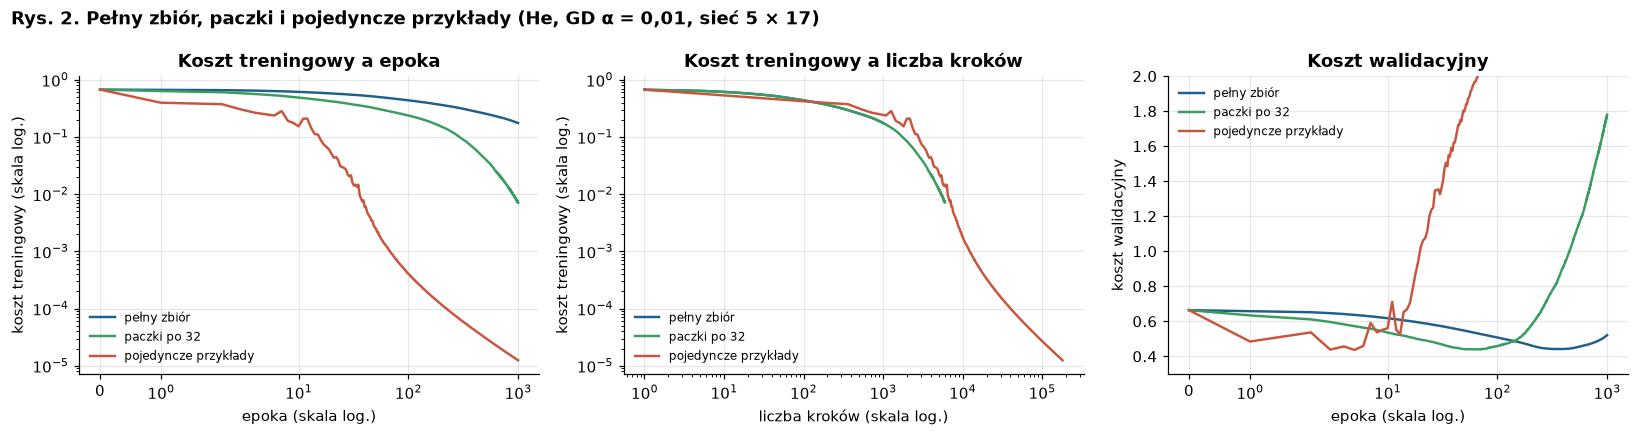

,kroków na epokę,epoki do kosztu ≤ 0.3,kroki do kosztu ≤ 0.3,czas do kosztu ≤ 0.3 [s],czas 1000 epok [s],min. koszt val,epoka min. val,F1 test (early stopping),koszt train po 1000 epok
pełny zbiór,1,398.3,398.0,0.118,0.3,0.447,464.3,0.762,1.5e-01
paczki po 32,6,66.3,398.0,0.059,0.92,0.446,82.7,0.77,4.8e-03
pojedyncze przykłady,181,4.0,724.0,0.075,17.61,0.462,3.7,0.779,9.6e-06


In [8]:
E_MODE = 1000
labels = {"full": "pełny zbiór", "minibatch": "paczki po 32", "single": "pojedyncze przykłady"}
rows, first_run = {}, {}
for mode in labels:
    runs = [train(MLP(d, NET, "he", seed=s), GD(0.01), Xtr, ytr, Xva, yva, mode=mode, epochs=E_MODE, seed=s) for s in SEEDS]
    first_run[mode] = runs[0]
    ep = [epochs_to(r.history, TARGET) for r in runs]
    idx = [r.history["epoch"].index(e) if e is not None else None for r, e in zip(runs, ep)]
    rows[labels[mode]] = {
        "kroków na epokę": runs[0].history["step"][1],
        f"epoki do kosztu ≤ {TARGET}": mean_or_dash(ep, 1),
        f"kroki do kosztu ≤ {TARGET}": mean_or_dash([r.history["step"][i] for r, i in zip(runs, idx) if i is not None], 0),
        f"czas do kosztu ≤ {TARGET} [s]": mean_or_dash([r.history["time"][i] for r, i in zip(runs, idx) if i is not None], 3),
        "czas 1000 epok [s]": mean_or_dash([r.history["time"][-1] for r in runs], 2),
        "min. koszt val": mean_or_dash([r.best_val_loss for r in runs]),
        "epoka min. val": mean_or_dash([r.best_epoch for r in runs], 1),
        "F1 test (early stopping)": mean_or_dash([early_f1(r, Xte, yte) for r in runs]),
        "koszt train po 1000 epok": f"{np.mean([r.history['loss'][-1] for r in runs]):.1e}"}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for mode, label in labels.items():
    h = first_run[mode].history
    ax[0].plot(h["epoch"], h["loss"], c=C[mode], lw=1.6, label=label)
    ax[1].plot(np.maximum(h["step"], 1), h["loss"], c=C[mode], lw=1.6, label=label)
    ax[2].plot(h["epoch"], h["val_loss"], c=C[mode], lw=1.6, label=label)
ax[0].set(xscale="symlog", yscale="log", xlabel="epoka (skala log.)", ylabel="koszt treningowy (skala log.)", title="Koszt treningowy a epoka")
ax[1].set(xscale="log", yscale="log", xlabel="liczba kroków (skala log.)", ylabel="koszt treningowy (skala log.)", title="Koszt treningowy a liczba kroków")
ax[2].set(xscale="symlog", ylim=(0.3, 2), xlabel="epoka (skala log.)", ylabel="koszt walidacyjny", title="Koszt walidacyjny")
for a in ax:
    a.legend(fontsize=8)
rys(fig, 2, "Pełny zbiór, paczki i pojedyncze przykłady (He, GD α = 0,01, sieć 5 × 17)")
pd.DataFrame(rows).T

**Jak czytać Rys. 2:** niebieska linia to pełny zbiór, zielona paczki po 32, czerwona pojedyncze przykłady (jedno losowanie). Lewy wykres: koszt treningowy w funkcji epok. Środkowy: ten sam koszt w funkcji liczby kroków (aktualizacji wag). Prawy: koszt walidacyjny w funkcji epok.

**Obserwacje:**
- **liczony w epokach**: pojedyncze przykłady dochodzą do kosztu 0,3 po **4** epokach, paczki po 66, pełny zbiór po 398. To prosta konsekwencja liczby kroków na epokę: 181, 6 i 1,
- **liczony w krokach**: wszystkie trzy tryby potrzebują podobnej liczby kroków (398–724). Pojedyncze przykłady potrzebują ich nawet więcej, bo gradient z jednego pacjenta jest bardzo zaszumiony (koszt skacze, Rys. 2, środek),
- **liczony w czasie**: pełny zbiór i paczki dochodzą do celu w ok. 0,06–0,13 s, a 1000 epok na pojedynczych przykładach trwa ok. 15 s zamiast 0,3 s, bo 181 małych mnożeń macierzy jest dużo wolniejsze niż jedno duże,
- szum w SGD i w paczkach to też szansa na wyjście z płaskiego obszaru, bo nie liczymy dokładnej funkcji kosztu, tylko jej przybliżenie,
- najniższy koszt walidacyjny (0,45–0,46) i F1 testowe przy early stopping (0,76–0,78) są podobne dla wszystkich trybów, ale osiągane w epoce ok. 464, 83 i 4. Szybsze tryby równie szybko się **przeuczają**: na pojedynczych przykładach koszt walidacyjny przekracza 2 już po ok. 60 epokach.

> **Wniosek:** tryb uczenia zmienia głównie to, ile kroków przypada na epokę. Paczki są kompromisem: tyle samo postępu na krok co pełny zbiór, szum, który pomaga opuścić płaskie obszary, i wydajne obliczenia macierzowe. Pojedyncze przykłady są najszybsze w epokach, ale najwolniejsze w czasie i najbardziej zaszumione.

> 🗣 **Co mówię:**
>
> Tryby uczenia. Na lewym wykresie, liczone w epokach, pojedyncze przykłady dochodzą do kosztu 0,3 po 4 epokach, paczki po 66, pełny zbiór po 398. To wynika z liczby kroków na epokę: 181, 6 i 1.
>
> Na środkowym, liczone w krokach, wszystkie potrzebują podobnie: 400–700. Pojedyncze przykłady są najbardziej zaszumione, koszt skacze.
>
> W czasie najszybsze są paczki. 1000 epok na pojedynczych przykładach trwa 15 s zamiast 0,3 s, bo 181 małych mnożeń jest wolniejsze niż jedno duże.
>
> Na prawym widać, że szybsze tryby szybciej się przeuczają. F1 jest podobne, 0,76–0,78.

## 5. Inicjalizacja wag

Sieć 5 × 17, paczki po 32, prosty gradient α = 0,01, **500 epok**, 3 losowania. Na środkowym i prawym wykresie: odchylenie wyjść kolejnych warstw liniowych i norma gradientu ich wag na starcie uczenia.

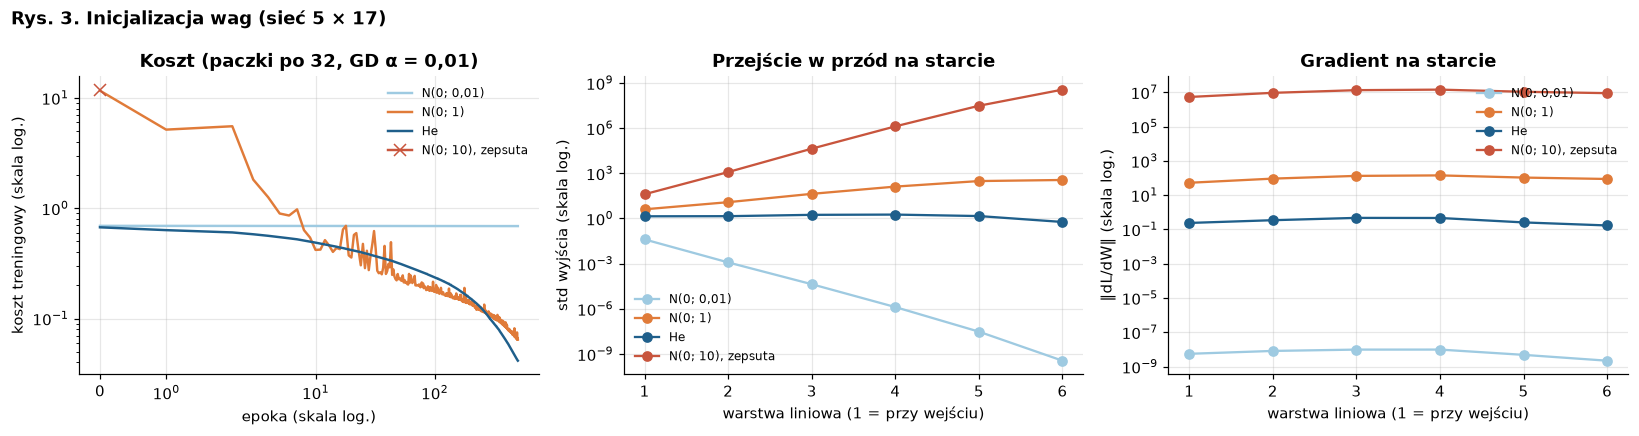

,std wyjścia ost. warstwy,‖dL/dW‖ 1. warstwy,koszt start,NaN (z 3),wyjście z plateau,epoki do kosztu ≤ 0.3,min. koszt val,F1 test (early stopping)
"N(0; 0,01)",3.6e-10,5.6e-09,0.693,0,—,—,0.69,0.0
N(0; 1),3.6e+02,5.3e+01,12.426,0,7.7,22.7,1.867,0.502
He,5.9e-01,2.4e-01,0.737,0,7.0,66.3,0.446,0.77
"N(0; 10), zepsuta",3.6e+08,5.3e+06,13.129,2,—,—,0.674,0.067


In [9]:
E_INIT = 500
inits = [("N(0; 0,01)", "normal", 0.01, "#9ecae1"), ("N(0; 1)", "normal", 1.0, "#e07b39"),
         ("He", "he", 1.0, "#1f5f8b"), ("N(0; 10), zepsuta", "normal", 10.0, "#c8553d")]
rows = {}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
with np.errstate(all="ignore"):                      # N(0; 10) celowo przepełnia liczby
    for label, kind, sc, col in inits:
        models = [MLP(d, NET, kind, sc, seed=s) for s in SEEDS]
        A, stds = Xtr, []
        for layer in models[0].layers:               # odchylenie wyjść warstw liniowych na starcie
            A = layer.forward(A)
            if isinstance(layer, Linear):
                stds.append(np.std(A))
        models[0].loss_and_grad(Xtr, ytr)
        grads0 = [np.sqrt(np.sum(l.dW ** 2)) for l in models[0].linears]
        runs = [train(m, GD(0.01), Xtr, ytr, Xva, yva, mode="minibatch", epochs=E_INIT, seed=s) for m, s in zip(models, SEEDS)]
        rows[label] = {"std wyjścia ost. warstwy": f"{stds[-1]:.1e}", "‖dL/dW‖ 1. warstwy": f"{grads0[0]:.1e}",
                       "koszt start": mean_or_dash([r.history["loss"][0] for r in runs]),
                       "NaN (z 3)": sum(not np.isfinite(r.history["loss"][-1]) for r in runs),
                       "wyjście z plateau": mean_or_dash([epochs_to(r.history, PLATEAU) for r in runs], 1),
                       f"epoki do kosztu ≤ {TARGET}": mean_or_dash([epochs_to(r.history, TARGET) for r in runs], 1),
                       "min. koszt val": mean_or_dash([r.best_val_loss if np.isfinite(r.best_val_loss) else None for r in runs]),
                       "F1 test (early stopping)": mean_or_dash([early_f1(r, Xte, yte) for r in runs])}
        h = runs[0].history
        ax[0].plot(h["epoch"], h["loss"], c=col, lw=1.6, marker="x" if not np.isfinite(h["loss"][-1]) else None, ms=8, label=label)
        ax[1].plot(range(1, len(stds) + 1), stds, marker="o", c=col, label=label)
        ax[2].plot(range(1, len(grads0) + 1), grads0, marker="o", c=col, label=label)
ax[0].set(xscale="symlog", yscale="log", xlabel="epoka (skala log.)", ylabel="koszt treningowy (skala log.)", title="Koszt (paczki po 32, GD α = 0,01)")
ax[1].set(yscale="log", xlabel="warstwa liniowa (1 = przy wejściu)", ylabel="std wyjścia (skala log.)", title="Przejście w przód na starcie")
ax[2].set(yscale="log", xlabel="warstwa liniowa (1 = przy wejściu)", ylabel="‖dL/dW‖ (skala log.)", title="Gradient na starcie")
for a in ax:
    a.legend(fontsize=8)
rys(fig, 3, "Inicjalizacja wag (sieć 5 × 17)")
pd.DataFrame(rows).T

**Jak czytać Rys. 3:** jasnoniebieska linia to N(0; 0,01), pomarańczowa N(0; 1), ciemnoniebieska He, czerwona N(0; 10). Lewy wykres: koszt treningowy (krzyżyk = koszt NaN). Środkowy: odchylenie wyjścia każdej warstwy liniowej na starcie, czyli jak duży jest sygnał (warstwa 1 przy wejściu). Prawy: wielkość gradientu wag każdej warstwy na starcie. Oś y logarytmiczna.

**Obserwacje:**
- **N(0; 0,01)** (jak w cz. 1): sygnał maleje ok. 30 razy na warstwę, na wyjściu ma odchylenie ok. $4\cdot10^{-10}$, a gradient wszystkich warstw to ok. $10^{-8}$. Sieć przez 500 epok zostaje na koszcie 0,69 i zwraca dla wszystkich tę samą odpowiedź (F1 = 0). To płaskowyż wynikający z **zanikających gradientów**,
- **N(0; 1)**: sygnał rośnie ok. 3 razy na warstwę (odchylenie 360 na wyjściu), koszt startowy to ok. 12, a gradient ok. 50–140. Sieć szybko obniża koszt treningowy (0,3 po ok. 23 epokach), ale skrajnie się przeucza: najniższy koszt walidacyjny to ok. 1,9, a F1 testowe tylko **0,50**. Gigantyczne początkowe wagi zostają w sieci i dają „pewne” i losowe odpowiedzi na nowych danych,
- **He**: odchylenie sygnału zostaje bliskie 1 w każdej warstwie (1,4 → 0,6), gradient ok. 0,2–0,5 w każdej warstwie. Koszt startowy 0,74, koszt 0,3 po ok. 66 epokach, najniższy koszt walidacyjny 0,45 i F1 testowe **0,77**,
- **N(0; 10), zepsuta**: sygnał rośnie ok. 30 razy na warstwę ($4\cdot10^{8}$ na wyjściu), gradient ok. $10^{7}$. W 2 z 3 losowań pierwszy krok wyrzuca wagi tak daleko, że po 1–2 epokach koszt to **NaN** (przepełnienie). W trzecim losowaniu ogromny krok „zabija” wszystkie neurony ReLU (zawsze ujemne wejście, zerowy gradient) i sieć na stałe zwraca jedną odpowiedź (koszt 0,690, F1 = 0). Średnie F1 w tabeli (0,07) pochodzi z wag sprzed wybuchu i z martwej sieci, czyli w praktyce F1 ≈ 0.

> **Wniosek:** inicjalizacja decyduje, czy uczenie w ogóle ruszy. Za małe wagi dają zanikające gradienty (sieć stoi), za duże wagi eksplodujące gradienty (NaN albo martwe neurony) albo model, który się uczy, ale źle generalizuje. Inicjalizacja He zachowuje wariancję sygnału w obie strony i daje stabilne uczenie od pierwszej epoki.

> 🗣 **Co mówię:**
>
> Inicjalizacja. Środkowy wykres pokazuje sygnał w kolejnych warstwach na starcie.
>
> Przy N(0; 0,01) sygnał maleje ok. 30 razy na warstwę, gradient ma 10⁻⁸ i sieć stoi na koszcie 0,69 przez całe uczenie.
>
> Przy N(0; 1) sygnał rośnie ok. 3 razy na warstwę, koszt startowy to 12. Sieć się uczy, ale F1 na teście tylko 0,50.
>
> Przy N(0; 10) rośnie 30 razy na warstwę: po 1–2 epokach koszt to NaN albo wszystkie ReLU są martwe.
>
> He trzyma sygnał na poziomie ok. 1 w każdej warstwie i daje F1 0,77.

## 6. Prosty gradient a ADAM

Sieć 5 × 17, pełny zbiór, **3000 epok**, 3 losowania, dwa punkty startowe: dobra inicjalizacja (He) i płaskowyż z cz. 1 (N(0; 0,01)). ADAM z α = 0,001 (wartość domyślna) i α = 0,01 (ta sama co w GD).

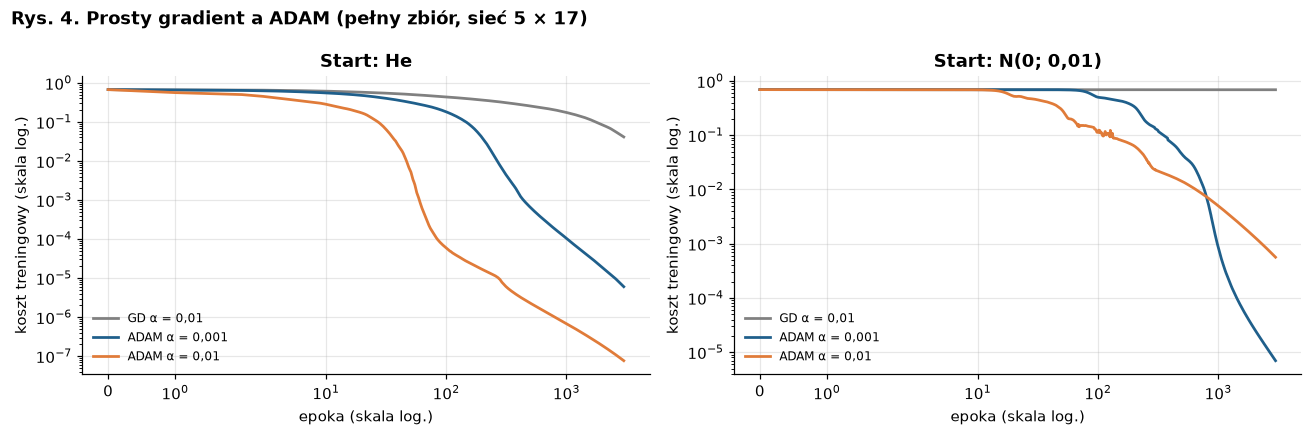

wyjście z plateau (3 losowania)  \
He         GD α = 0,01                       14 / 61 / 38   
           ADAM α = 0,001                      6 / 20 / 7   
           ADAM α = 0,01                        1 / 3 / 1   
N(0; 0,01) GD α = 0,01                          — / — / —   
           ADAM α = 0,001                    85 / 88 / 90   
           ADAM α = 0,01                     18 / 18 / 17   

                          epoki do kosztu ≤ 0.3 koszt train po 3000  \
He         GD α = 0,01                    398.3             2.6e-02   
           ADAM α = 0,001                  63.0             8.1e-06   
           ADAM α = 0,01                   10.3             1.4e-07   
N(0; 0,01) GD α = 0,01                        —             6.9e-01   
           ADAM α = 0,001                 197.7             3.8e-03   
           ADAM α = 0,01                   62.7             6.7e-02   

                          min. koszt val epoka min. val  \
He         GD α = 0,01             0.447          464.3   
           ADAM α = 0,001          0.465           66.3   
           ADAM α = 0,01           0.457            9.7   
N(0; 0,01) GD α = 0,01              0.69         1797.7   
           ADAM α = 0,001          0.378          235.0   
           ADAM α = 0,01           0.368           72.0   

                          F1 test (early stopping)  
He         GD α = 0,01                       0.762  
           ADAM α = 0,001                    0.771  
           ADAM α = 0,01                     0.769  
N(0; 0,01) GD α = 0,01                         0.0  
           ADAM α = 0,001                    0.772  
           ADAM α = 0,01                     0.761

In [10]:
E_OPT = 3000
opts = [("GD α = 0,01", lambda: GD(0.01), C["gd"]), ("ADAM α = 0,001", lambda: Adam(0.001), C["adam_small"]),
        ("ADAM α = 0,01", lambda: Adam(0.01), C["adam_big"])]
rows = {}
fig, ax = plt.subplots(1, 2)
for i, (start, kind, sc) in enumerate([("He", "he", 1.0), ("N(0; 0,01)", "normal", 0.01)]):
    for label, make, col in opts:
        runs = [train(MLP(d, NET, kind, sc, seed=s), make(), Xtr, ytr, Xva, yva, mode="full", epochs=E_OPT, seed=s) for s in SEEDS]
        exits = [epochs_to(r.history, PLATEAU) for r in runs]
        rows[(start, label)] = {"wyjście z plateau (3 losowania)": " / ".join("—" if e is None else str(e) for e in exits),
                                f"epoki do kosztu ≤ {TARGET}": mean_or_dash([epochs_to(r.history, TARGET) for r in runs], 1),
                                "koszt train po 3000": f"{np.mean([r.history['loss'][-1] for r in runs]):.1e}",
                                "min. koszt val": mean_or_dash([r.best_val_loss for r in runs]),
                                "epoka min. val": mean_or_dash([r.best_epoch for r in runs], 1),
                                "F1 test (early stopping)": mean_or_dash([early_f1(r, Xte, yte) for r in runs])}
        ax[i].plot(runs[0].history["epoch"], runs[0].history["loss"], c=col, lw=1.8, label=label)
    ax[i].set(xscale="symlog", yscale="log", xlabel="epoka (skala log.)", ylabel="koszt treningowy (skala log.)", title=f"Start: {start}")
    ax[i].legend(fontsize=8)
rys(fig, 4, "Prosty gradient a ADAM (pełny zbiór, sieć 5 × 17)")
pd.DataFrame(rows).T

**Jak czytać Rys. 4:** lewy wykres: start z inicjalizacji He, prawy: start z N(0; 0,01) jak w części 1. Szara linia to prosty gradient (α = 0,01), niebieska ADAM α = 0,001, pomarańczowa ADAM α = 0,01. Obie osie logarytmiczne.

**Obserwacje:**
- **start He**: ADAM dochodzi do kosztu 0,3 po ok. **63** (α = 0,001) i **10** epokach (α = 0,01), a prosty gradient po 398. Po 3000 epokach ADAM ma koszt treningowy $10^{-5}$–$10^{-7}$, czyli zapamiętał zbiór treningowy,
- **start N(0; 0,01)**: prosty gradient w żadnym losowaniu nie zszedł z płaskowyżu przez 3000 epok (koszt 0,690, F1 = 0). ADAM wychodzi z niego po ok. **85–90** (α = 0,001) i **17–18** epokach (α = 0,01). Gradient ok. $10^{-8}$ jest dla ADAM tak samo dobry jak gradient ok. 1, bo krok to $\alpha \cdot \hat m / \sqrt{\hat v}$, czyli ok. α niezależnie od skali,
- jakość jest podobna wszędzie, gdzie uczenie ruszyło: najniższy koszt walidacyjny 0,37–0,47, F1 testowe przy early stopping 0,76–0,77. ADAM osiąga ją po kilkudziesięciu epokach zamiast kilkuset,
- szybkie uczenie wymaga szybkiego warunku stopu: przy ADAM α = 0,01 najlepsza na walidacji jest ok. 10. epoka (start He).

> **Wniosek:** ADAM łączy momentum (przejście przez punkt siodłowy „z rozpędu”) ze skalowaniem kroku odwrotnością wielkości gradientu (przyspieszenie na płaskich obszarach). Dzięki temu uczy się kilka do kilkudziesięciu razy szybciej i radzi sobie nawet z inicjalizacją, przy której prosty gradient stoi w miejscu. Nie poprawia jednak jakości ponad to, co daje dobrze zatrzymany prosty gradient.

> 🗣 **Co mówię:**
>
> Prosty gradient i ADAM, dwa punkty startowe.
>
> Na lewym, start z He: ADAM dochodzi do kosztu 0,3 po 10–63 epokach, prosty gradient po 398.
>
> Na prawym, start z wag 0,01 jak w części 1: prosty gradient nie ruszył przez 3000 epok w żadnym losowaniu. ADAM wychodzi z płaskowyżu po 17–90 epokach, bo dla niego gradient 10⁻⁸ jest tak samo dobry jak 1.
>
> Jakość jest podobna, F1 ok. 0,77. ADAM jest szybszy, ale też szybciej się przeucza, więc early stopping jest konieczny.

## 7. Podsumowanie

| porównanie | wynik | dowód |
|---|---|---|
| punkt siodłowy | GD ucieka po 91 krokach, ADAM po 6 | Rys. 1 |
| pełny zbiór vs paczki vs pojedyncze | 398 / 66 / 4 epok do kosztu 0,3, ale podobna liczba kroków; SGD najwolniejszy w czasie i najbardziej zaszumiony | Rys. 2 |
| inicjalizacja N(0; 0,01) | zanikające gradienty, sieć stoi na koszcie 0,69 | Rys. 3 |
| inicjalizacja N(0; 1) | eksplodujący sygnał, koszt startowy 12, F1 test 0,50 | Rys. 3 |
| inicjalizacja He | stabilny sygnał i gradient, F1 test 0,77 | Rys. 3 |
| inicjalizacja N(0; 10) | NaN po 1–2 epokach albo martwe neurony ReLU | Rys. 3 |
| GD vs ADAM (start He) | koszt 0,3 po 398 vs 10–63 epokach | Rys. 4 |
| GD vs ADAM (start N(0; 0,01)) | GD nie rusza w 3000 epok, ADAM wychodzi z płaskowyżu po 17–90 epokach | Rys. 4 |

> 🗣 **Co mówię:**
>
> W tabeli jest wszystko razem. Problemem były płaskie obszary, a nie minima lokalne. Inicjalizacja decyduje, czy uczenie w ogóle ruszy, ADAM z płaskowyżu wychodzi, a tryb uczenia to kompromis między szumem, liczbą kroków i czasem.

## 8. Wnioski

W sieci z pięcioma warstwami ukrytymi główną przeszkodą dla uczenia były płaskie obszary funkcji kosztu, a nie minima lokalne. Przy inicjalizacji N(0; 0,01) gradient wynosił ok. 10⁻⁸ i prosty spadek gradientu nie ruszał przez 3000 epok, choć sieć była w stanie się nauczyć. ADAM, który skaluje krok odwrotnością wielkości gradientu i dodaje momentum, wychodził z tego samego płaskowyżu po kilkudziesięciu epokach, a w punkcie siodłowym funkcji dwóch zmiennych uciekał po 6 krokach zamiast 91. Inicjalizacja decydowała o tym, czy uczenie w ogóle ruszy: za małe wagi powodowały zanikanie gradientu, odchylenie 1 eksplodujący sygnał i słabą generalizację (F1 0,50), a odchylenie 10 przepełnienie (NaN) albo martwe neurony. Inicjalizacja He zachowywała wariancję sygnału i dawała stabilne uczenie z F1 ok. 0,77. Tryb uczenia zmieniał głównie liczbę kroków na epokę: liczone w krokach wszystkie tryby uczyły się podobnie, paczki były najszybsze w czasie, a pojedyncze przykłady najbardziej zaszumione i najwolniejsze. Tam, gdzie uczenie ruszyło, jakość na zbiorze testowym była podobna (F1 0,76–0,78), ale szybsze metody wymagały szybszego warunku stopu, bo równie szybko się przeuczały.

> 🗣 **Co mówię:**
>
> Tu czytam swoje wnioski. Jeśli mam powiedzieć jedno zdanie: w głębokiej sieci gradient potrafi być prawie zerowy daleko od minimum, a dobra inicjalizacja i ADAM pozwalają z takiego miejsca wyjść.